# CGCNN: from formation energy to battery voltage

**Question.** A crystal-graph network (CGCNN, Xie & Grossman 2018) predicts formation energy well. Does that accuracy survive the *subtraction* a Li-ion cathode voltage requires?

**Pre-registered limits:** voltage MAE ≤ 0.25 V and Spearman ≥ 0.85.

| Experiment | Formation energy | Voltage MAE | Spearman | Verdict |
|---|---|---|---|---|
| Matbench fold 0 (random split) | 0.0327 eV/atom test MAE | – | – | reproduces the published ≈ 0.033 |
| L1: unseen electrode compounds (3,342 pairs) | 0.025 eV/atom at the endpoints | 0.331 V (95% CI 0.306–0.356) | 0.925 | MAE fails, Spearman passes |
| L2: unseen chemical systems (3,342 pairs) | 0.032 eV/atom at the endpoints | 0.409 V (95% CI 0.384–0.438) | 0.895 | MAE fails, Spearman passes |

Formation-energy errors are amplified about 13× in voltage because the two endpoints' errors are only weakly shared (correlation 0.19 at L1, 0.30 at L2). Three L2 training seeds agree (0.409 / 0.400 / 0.412 V); a 3-seed ensemble reaches 0.368 V; seed disagreement is a weak trust signal (Spearman 0.22 with the error).

**How to read this notebook.** Sections 1–4 reproduce CGCNN on Matbench (stand-alone version), 5 is a shared helper module, 6 analyses the errors, 7 pulls Materials Project data, 8–9 train the two hold-out models (T4 GPU), 10–13 are the voltage experiment and its diagnostics. Files are kept on Google Drive in `cgcnn_run/`. Materials Project database release 2026.09.28. Code developed with AI assistance (Claude, Anthropic).

## 1. Setup and Matbench data (fold 0)
Downloads `matbench_mp_e_form` (132,752 structures), writes them in CGCNN's folder format, and splits the official fold-0 training pool into train / validation (95,581 / 10,620). The official test fold (26,551 structures) is never used for model selection.

In [ ]:
!pip -q install matminer mp-api pymatgen
!pip -q install --no-deps matbench          # --no-deps on purpose
!git clone -q https://github.com/txie-93/cgcnn.git

import os, json, math, random, shutil, gc
import pandas as pd
import matbench
from matminer.datasets import load_dataset

ATOM_INIT = "cgcnn/data/sample-regression/atom_init.json"

def write_cgcnn_folder(structures, targets, ids, out_dir):
    """CIFs + id_prop.csv (no header) + atom_init.json: the layout CGCNN reads."""
    os.makedirs(out_dir, exist_ok=True)
    shutil.copy(ATOM_INIT, os.path.join(out_dir, "atom_init.json"))
    for sid, s in zip(ids, structures):
        s.to(filename=os.path.join(out_dir, f"{sid}.cif"))
    pd.DataFrame({"id": list(ids), "y": [float(y) for y in targets]}).to_csv(
        os.path.join(out_dir, "id_prop.csv"), header=False, index=False)

# Gate 0: Matbench formation energy, official fold 0
df = load_dataset("matbench_mp_e_form")      # columns: structure, e_form (eV/atom); big download, be patient
width = math.floor(math.log10(len(df))) + 1
df.index = [f"mb-mp-e-form-{i + 1:0{width}d}" for i in df.index]   # same ids Matbench's fold file uses

path = os.path.join(os.path.dirname(matbench.__file__), "matbench_v0.1_validation.json")
fold = json.load(open(path))["splits"]["matbench_mp_e_form"]["fold_0"]
pool, test = list(fold["train"]), list(fold["test"])               # 106,201 / 26,551
random.Random(0).shuffle(pool)
val, train = pool[: len(pool) // 10], pool[len(pool) // 10 :]      # validation comes out of train, never test

write_cgcnn_folder(df["structure"], df["e_form"], df.index, "/content/mp_eform")
json.dump({"train": train, "val": val, "test": test}, open("/content/mp_eform_split.json", "w"))
print(len(train), len(val), len(test))      # expect 95581 10620 26551

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
Fetching matbench_mp_e_form.json.gz from https://ml.materialsproject.org/projects/matbench_mp_e_form.json.gz to /usr/local/lib/python3.13/dist-packages/matminer/datasets/matbench_mp_e_form.json.gz


Fetching https://ml.materialsproject.org/projects/matbench_mp_e_form.json.gz in MB: 166.735872MB [00:00, 561.93MB/s]                                


95581 10620 26551


## 2. GPU check

In [ ]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

True Tesla T4


## 3. Build the crystal graphs once (stand-alone version)
12 nearest neighbours within 8 Å per atom, built exactly as CGCNN builds them, and saved to Google Drive in a single file.

In [ ]:
import os, warnings, numpy as np, pandas as pd
from multiprocessing import get_context
from google.colab import drive; drive.mount("/content/drive")
from tqdm.auto import tqdm
from pymatgen.core import Structure
warnings.filterwarnings("ignore")

ROOT = "/content/mp_eform"
GRAPHS = "/content/drive/MyDrive/cgcnn_run/graphs_mp_eform.npz"   # on Drive, so it survives disconnects
RADIUS, MAXN = 8.0, 12                                            # CGCNN's defaults

def build_one(cid):
    """Same graph CGCNN builds: 12 nearest neighbours within 8 A, padded with (index 0, distance 9) if fewer."""
    s = Structure.from_file(f"{ROOT}/{cid}.cif")
    Z = np.array([site.specie.Z for site in s], dtype=np.int16)
    idx = np.zeros((len(s), MAXN), dtype=np.int32)
    dist = np.full((len(s), MAXN), RADIUS + 1.0, dtype=np.float32)
    for i, nb in enumerate(s.get_all_neighbors(RADIUS, include_index=True)):
        nb = sorted(nb, key=lambda x: x[1])[:MAXN]
        idx[i, :len(nb)] = [x[2] for x in nb]
        dist[i, :len(nb)] = [x[1] for x in nb]
    return Z, idx, dist

lab = pd.read_csv(f"{ROOT}/id_prop.csv", header=None, names=["id", "y"])
with get_context("fork").Pool(os.cpu_count()) as p:
    res = list(tqdm(p.imap(build_one, lab.id, chunksize=64), total=len(lab)))
Z, idx, dist = (np.concatenate([r[k] for r in res]) for k in range(3))
start = np.concatenate([[0], np.cumsum([len(r[0]) for r in res])])
os.makedirs(os.path.dirname(GRAPHS), exist_ok=True)
np.savez(GRAPHS, ids=lab.id.values.astype(str), y=lab.y.values.astype(np.float32), start=start, Z=Z, idx=idx, dist=dist)
print(len(lab), "structures,", len(Z), "atoms ->", GRAPHS)
del res, Z, idx, dist                                              # free RAM

132752 structures, 3869658 atoms -> /content/drive/MyDrive/cgcnn_run/graphs_mp_eform.npz


## 4. Train CGCNN on Matbench fold 0
The repository's own model with a vectorised pooling step and a GPU-resident batch loader (the repository's loader was too slow on Colab). Adam, learning rate 1e-3 with cosine decay, batch size 256, 150 epochs. The checkpoint with the best validation MAE is evaluated once on the test fold.

In [ ]:
import os, sys, json, time, numpy as np, pandas as pd, torch, torch.nn as nn
from google.colab import drive; drive.mount("/content/drive")
sys.path.insert(0, "/content/cgcnn")
from cgcnn.model import CrystalGraphConvNet

GRAPHS = "/content/drive/MyDrive/cgcnn_run/graphs_mp_eform.npz"
SPLIT  = "/content/mp_eform_split.json"
RUN    = "/content/drive/MyDrive/cgcnn_run/run1"       # checkpoints, history and predictions land here
EPOCHS, BS, LR, SEED = 150, 256, 1e-3, 0
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(RUN, exist_ok=True); torch.manual_seed(SEED); np.random.seed(SEED)
print("device:", dev, torch.cuda.get_device_name(0) if dev.type == "cuda" else "(NO GPU: this will be slow)")

# ---- everything lives on the GPU: atoms, neighbour lists, targets ----
G = np.load(GRAPHS); ids = G["ids"]; pos = {c: i for i, c in enumerate(ids)}
T = lambda a, dt=None: torch.tensor(a, device=dev, dtype=dt)
start, Zall = T(G["start"], torch.long), T(G["Z"], torch.long)
idxall, distall, Y = T(G["idx"], torch.long), T(G["dist"], torch.float32), T(G["y"], torch.float32)
sp = json.load(open(SPLIT))
split = {k: T([pos[c] for c in sp[k]], torch.long) for k in ("train", "val", "test")}

ai = json.load(open("/content/cgcnn/data/sample-regression/atom_init.json"))
table = torch.zeros(101, 92)
for k, v in ai.items(): table[int(k)] = torch.tensor(v)
table = table.to(dev)
filt = T(np.arange(0, 8.0 + 0.2, 0.2), torch.float32)   # CGCNN's 41 Gaussian centres (width 0.2)

def batch(cids):
    """Assemble a batch of crystals on the GPU, no Python loops."""
    s = start[cids]; n = start[cids + 1] - s
    off = torch.cumsum(n, 0) - n                                   # first atom of each crystal inside the batch
    bvec = torch.repeat_interleave(torch.arange(len(cids), device=dev), n)   # crystal of every atom
    a = s[bvec] + torch.arange(len(bvec), device=dev) - off[bvec]  # global atom index
    nbr_fea = torch.exp(-((distall[a].unsqueeze(-1) - filt) ** 2) / 0.2 ** 2)
    return table[Zall[a]], nbr_fea, idxall[a] + off[bvec].unsqueeze(1), (bvec, n)

class FastCGCNN(CrystalGraphConvNet):                            # the repo's own model; only pooling is vectorised
    def pooling(self, atom_fea, crystal_atom_idx):
        bvec, n = crystal_atom_idx
        out = torch.zeros(len(n), atom_fea.shape[1], device=atom_fea.device, dtype=atom_fea.dtype)
        return out.index_add_(0, bvec, atom_fea) / n.unsqueeze(1).to(atom_fea.dtype)

model = FastCGCNN(92, len(filt), atom_fea_len=64, n_conv=3, h_fea_len=128, n_h=1).to(dev)
mu, sd = Y[split["train"]].mean(), Y[split["train"]].std()
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-5)

@torch.no_grad()
def evaluate(cids, bs=1024):
    model.eval()
    p = torch.cat([model(*batch(cids[i:i + bs])).squeeze(1) * sd + mu for i in range(0, len(cids), bs)])
    return (p - Y[cids]).abs().mean().item(), p

hist, best, ep0, ck = [], 1e9, 0, f"{RUN}/last.pt"
if os.path.exists(ck):                                           # resume after a disconnect
    c = torch.load(ck, map_location=dev, weights_only=False)
    model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"]); sched.load_state_dict(c["sched"])
    hist, best, ep0 = c["hist"], c["best"], c["epoch"] + 1
    print("resumed at epoch", ep0)

tr = split["train"]
for ep in range(ep0, EPOCHS):
    t0 = time.time(); model.train(); tot = torch.zeros((), device=dev)
    perm = tr[torch.randperm(len(tr), device=dev)]
    for i in range(0, len(perm), BS):
        b = perm[i:i + BS]
        if len(b) < 8: continue                                  # BatchNorm needs more than a couple of atoms
        loss = nn.functional.mse_loss(model(*batch(b)).squeeze(1), (Y[b] - mu) / sd)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        tot += loss.detach() * len(b)
    sched.step()
    vmae, _ = evaluate(split["val"])
    hist.append(dict(epoch=ep, train_loss=tot.item() / len(tr), val_mae=vmae, lr=sched.get_last_lr()[0], sec=time.time() - t0))
    if vmae < best:
        best = vmae; torch.save(model.state_dict(), f"{RUN}/best.pt")
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), hist=hist, best=best, epoch=ep), ck)
    if ep < 3 or ep % 5 == 0 or ep == EPOCHS - 1:
        print(f"epoch {ep:3d} | val MAE {vmae:.4f} (best {best:.4f}) | {hist[-1]['sec']:.0f}s")

# ---- final: test MAE with the best-validation weights, plus predictions for error analysis ----
model.load_state_dict(torch.load(f"{RUN}/best.pt", map_location=dev))
tmae, p = evaluate(split["test"])
print(f"TEST MAE {tmae:.4f} eV/atom   (best validation MAE {best:.4f})")
pd.DataFrame(dict(id=ids[split["test"].cpu().numpy()], y_true=Y[split["test"]].cpu().numpy(), y_pred=p.cpu().numpy())).to_csv(f"{RUN}/test_predictions.csv", index=False)
pd.DataFrame(hist).to_csv(f"{RUN}/history.csv", index=False)

device: cuda Tesla T4
epoch   0 | val MAE 0.1428 (best 0.1428) | 12s
epoch   1 | val MAE 0.1556 (best 0.1428) | 11s
epoch   2 | val MAE 0.1208 (best 0.1208) | 12s
epoch   5 | val MAE 0.1097 (best 0.0889) | 12s
epoch  10 | val MAE 0.0823 (best 0.0823) | 14s
epoch  15 | val MAE 0.0736 (best 0.0713) | 14s
epoch  20 | val MAE 0.0721 (best 0.0669) | 14s
epoch  25 | val MAE 0.1173 (best 0.0647) | 14s
epoch  30 | val MAE 0.0734 (best 0.0640) | 14s
epoch  35 | val MAE 0.0540 (best 0.0491) | 14s
epoch  40 | val MAE 0.0640 (best 0.0491) | 14s
epoch  45 | val MAE 0.0590 (best 0.0491) | 14s
epoch  50 | val MAE 0.0504 (best 0.0438) | 14s
epoch  55 | val MAE 0.0439 (best 0.0438) | 14s
epoch  60 | val MAE 0.0464 (best 0.0433) | 14s
epoch  65 | val MAE 0.0411 (best 0.0411) | 14s
epoch  70 | val MAE 0.0534 (best 0.0403) | 14s
epoch  75 | val MAE 0.0388 (best 0.0388) | 14s
epoch  80 | val MAE 0.0374 (best 0.0374) | 14s
epoch  85 | val MAE 0.0389 (best 0.0365) | 14s
epoch  90 | val MAE 0.0382 (best 0.036

## 5. Shared helper module
Packages the logic of Sections 3–4 as functions (`build_graphs`, `train`) saved to Drive as `fastcgcnn.py`; on a synthetic set it reproduces the stand-alone version exactly (same graphs, same learning curve). Sections 7–12 import it.

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
import os, sys, subprocess, importlib.util
for pkg, mod in (("pymatgen", "pymatgen"), ("mp-api", "mp_api")):       # install only if this runtime lacks them
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "-q", "install", pkg], check=True)
os.makedirs("/content/drive/MyDrive/cgcnn_run", exist_ok=True)

MODULE = r'''
# fastcgcnn.py: helpers shared by the later cells (written to your Drive by Cell 5)
import os, sys, json, time, subprocess, warnings
from functools import partial
import numpy as np, pandas as pd

DRIVE = "/content/drive/MyDrive/cgcnn_run"
REPO = "/content/cgcnn"
RADIUS, MAXN = 8.0, 12                      # CGCNN defaults: 12 nearest neighbours within 8 A

def ensure_repo():
    # clone the CGCNN repo if this runtime does not have it, and make it importable
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/txie-93/cgcnn.git", REPO], check=True)
    if REPO not in sys.path:
        sys.path.insert(0, REPO)
    return f"{REPO}/data/sample-regression/atom_init.json"

def _build_one(cid, root):
    # same graph CGCNN builds: 12 nearest neighbours within 8 A, padded with (index 0, distance 9) if fewer
    from pymatgen.core import Structure
    s = Structure.from_file(f"{root}/{cid}.cif")
    Z = np.array([site.specie.Z for site in s], dtype=np.int16)
    idx = np.zeros((len(s), MAXN), dtype=np.int32)
    dist = np.full((len(s), MAXN), RADIUS + 1.0, dtype=np.float32)
    for i, nb in enumerate(s.get_all_neighbors(RADIUS, include_index=True)):
        nb = sorted(nb, key=lambda x: x[1])[:MAXN]
        idx[i, :len(nb)] = [x[2] for x in nb]
        dist[i, :len(nb)] = [x[1] for x in nb]
    return Z, idx, dist

def build_graphs(root, out):
    # one-time job: build every crystal graph in `root` (CIFs + id_prop.csv) and save them in one file
    if os.path.exists(out):
        print("graphs already built, skipping:", out); return
    if not os.path.exists(f"{root}/id_prop.csv"):
        raise FileNotFoundError(f"{root}/id_prop.csv not found: run the cell that creates {root} first")
    from multiprocessing import get_context
    from tqdm.auto import tqdm
    warnings.filterwarnings("ignore")
    lab = pd.read_csv(f"{root}/id_prop.csv", header=None, names=["id", "y"])
    with get_context("fork").Pool(os.cpu_count()) as p:
        res = list(tqdm(p.imap(partial(_build_one, root=root), lab.id, chunksize=64), total=len(lab)))
    Z, idx, dist = (np.concatenate([r[k] for r in res]) for k in range(3))
    start = np.concatenate([[0], np.cumsum([len(r[0]) for r in res])])
    os.makedirs(os.path.dirname(out), exist_ok=True)
    tmp = out + ".tmp.npz"                  # write to a temp name first, so a half-written file is never mistaken for a finished one
    np.savez(tmp, ids=lab.id.values.astype(str), y=lab.y.values.astype(np.float32), start=start, Z=Z, idx=idx, dist=dist)
    os.replace(tmp, out)
    print(len(lab), "structures,", len(Z), "atoms ->", out)

def train(graphs, split, run, epochs=150, bs=256, lr=1e-3, seed=0):
    # train CGCNN on the split in `split` (json with train/val/test ids); checkpoints + predictions go to the folder `run`
    import torch, torch.nn as nn
    atom_init = ensure_repo()
    from cgcnn.model import CrystalGraphConvNet
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    os.makedirs(run, exist_ok=True); torch.manual_seed(seed); np.random.seed(seed)
    print("device:", dev, torch.cuda.get_device_name(0) if dev.type == "cuda" else "(NO GPU: this will be slow)")

    # ---- everything lives on the GPU: atoms, neighbour lists, targets ----
    G = np.load(graphs); ids = G["ids"]; pos = {c: i for i, c in enumerate(ids)}
    T = lambda a, dt=None: torch.tensor(a, device=dev, dtype=dt)
    start, Zall = T(G["start"], torch.long), T(G["Z"], torch.long)
    idxall, distall, Y = T(G["idx"], torch.long), T(G["dist"], torch.float32), T(G["y"], torch.float32)
    sj = json.load(open(split))
    assert not (set(sj["train"]) & set(sj["test"])) and not (set(sj["val"]) & set(sj["test"])) and not (set(sj["train"]) & set(sj["val"])), "train/val/test overlap!"
    sp = {k: T([pos[c] for c in sj[k]], torch.long) for k in ("train", "val", "test")}
    print("train / val / test =", len(sp["train"]), len(sp["val"]), len(sp["test"]), "(no overlap, checked)")

    ai = json.load(open(atom_init))
    table = torch.zeros(101, 92)
    for k, v in ai.items(): table[int(k)] = torch.tensor(v)
    table = table.to(dev)
    filt = T(np.arange(0, 8.0 + 0.2, 0.2), torch.float32)   # CGCNN's 41 Gaussian centres (width 0.2)

    def batch(cids):
        # assemble a batch of crystals on the GPU, no Python loops
        s = start[cids]; n = start[cids + 1] - s
        off = torch.cumsum(n, 0) - n                                   # first atom of each crystal inside the batch
        bvec = torch.repeat_interleave(torch.arange(len(cids), device=dev), n)   # crystal of every atom
        a = s[bvec] + torch.arange(len(bvec), device=dev) - off[bvec]  # global atom index
        nbr_fea = torch.exp(-((distall[a].unsqueeze(-1) - filt) ** 2) / 0.2 ** 2)
        return table[Zall[a]], nbr_fea, idxall[a] + off[bvec].unsqueeze(1), (bvec, n)

    class FastCGCNN(CrystalGraphConvNet):                              # the repo's own model; only pooling is vectorised
        def pooling(self, atom_fea, crystal_atom_idx):
            bvec, n = crystal_atom_idx
            out = torch.zeros(len(n), atom_fea.shape[1], device=atom_fea.device, dtype=atom_fea.dtype)
            return out.index_add_(0, bvec, atom_fea) / n.unsqueeze(1).to(atom_fea.dtype)

    model = FastCGCNN(92, len(filt), atom_fea_len=64, n_conv=3, h_fea_len=128, n_h=1).to(dev)
    mu, sd = Y[sp["train"]].mean(), Y[sp["train"]].std()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-5)

    @torch.no_grad()
    def evaluate(cids, ebs=1024):
        model.eval()
        p = torch.cat([model(*batch(cids[i:i + ebs])).squeeze(1) * sd + mu for i in range(0, len(cids), ebs)])
        return (p - Y[cids]).abs().mean().item(), p

    hist, best, ep0, ck = [], 1e9, 0, f"{run}/last.pt"
    if os.path.exists(ck):                                             # resume after a disconnect
        c = torch.load(ck, map_location=dev, weights_only=False)
        model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"]); sched.load_state_dict(c["sched"])
        hist, best, ep0 = c["hist"], c["best"], c["epoch"] + 1
        print("resumed at epoch", ep0)

    tr = sp["train"]
    for ep in range(ep0, epochs):
        t0 = time.time(); model.train(); tot = torch.zeros((), device=dev)
        perm = tr[torch.randperm(len(tr), device=dev)]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            if len(b) < 8: continue                                    # BatchNorm needs more than a couple of atoms
            loss = nn.functional.mse_loss(model(*batch(b)).squeeze(1), (Y[b] - mu) / sd)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tot += loss.detach() * len(b)
        sched.step()
        vmae, _ = evaluate(sp["val"])
        hist.append(dict(epoch=ep, train_loss=tot.item() / len(tr), val_mae=vmae, lr=sched.get_last_lr()[0], sec=time.time() - t0))
        if vmae < best:
            best = vmae; torch.save(model.state_dict(), f"{run}/best.pt")
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), hist=hist, best=best, epoch=ep), ck)
        if ep < 3 or ep % 5 == 0 or ep == epochs - 1:
            print(f"epoch {ep:3d} | val MAE {vmae:.4f} (best {best:.4f}) | {hist[-1]['sec']:.0f}s")

    # ---- final: test MAE with the best-validation weights, plus predictions for error analysis ----
    model.load_state_dict(torch.load(f"{run}/best.pt", map_location=dev))
    tmae, p = evaluate(sp["test"])
    print(f"TEST MAE {tmae:.4f} eV/atom   (best validation MAE {best:.4f})")
    pd.DataFrame(dict(id=ids[sp["test"].cpu().numpy()], y_true=Y[sp["test"]].cpu().numpy(), y_pred=p.cpu().numpy())).to_csv(f"{run}/test_predictions.csv", index=False)
    pd.DataFrame(hist).to_csv(f"{run}/history.csv", index=False)
    return dict(test_mae=tmae, best_val=best)
'''
open("/content/drive/MyDrive/cgcnn_run/fastcgcnn.py", "w").write(MODULE.lstrip("\n"))
print("helper module written to Drive; later cells import it")

helper module written to Drive; later cells import it


## 6. Error analysis of the Matbench model
Test MAE overall and by chemistry. 'Sparse' structures (some atom has fewer than 12 neighbours within 8 Å) are 1.2% of the test set and carry about 3% of the total error. The worst predictions are elemental N₂ phases (true value 0 eV/atom) and a few exotic compounds.

TEST MAE 0.0327 | mean-predictor MAE 1.006 | median 0.0185 | 90th pct 0.070 | 99th pct 0.236 | max 3.44
best validation epoch: 146 of 149
                           group     n    MAE  median AE
                             ALL 26551 0.0327     0.0185
sparse graph (padded neighbours)   325 0.0870     0.0551
        everything except sparse 26226 0.0320     0.0183
                      contains O 12964 0.0277     0.0162
           halide (F, Cl, Br, I)  4275 0.0332     0.0194
        chalcogenide (S, Se, Te)  3944 0.0339     0.0206
                      contains H  1977 0.0305     0.0187
             3d transition metal 12455 0.0275     0.0161
           lanthanide / actinide  7093 0.0349     0.0200
      alkali (Li, Na, K, Rb, Cs)  8006 0.0240     0.0145
                    1-2 elements  4082 0.0532     0.0265
                      3 elements 12271 0.0341     0.0207
                     4+ elements 10198 0.0228     0.0144

10 worst predictions:
                 id formula  sites  spars

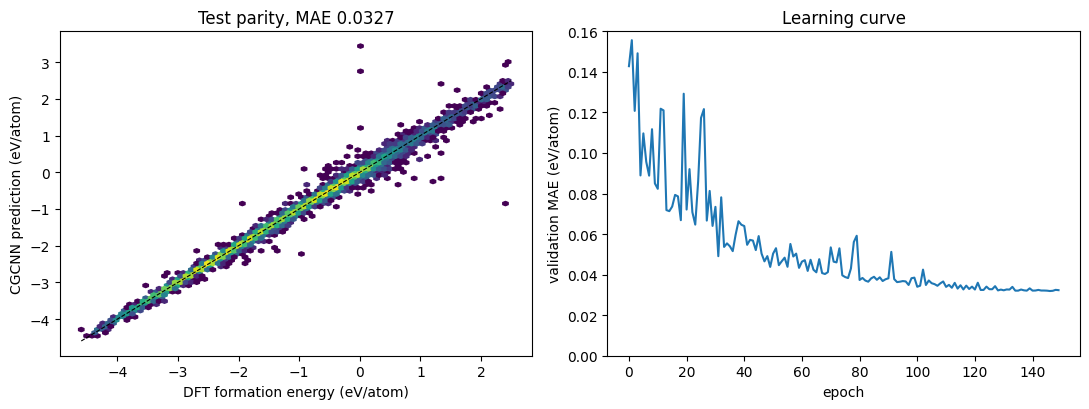

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pymatgen.core import Composition
from pymatgen.core.periodic_table import Element
warnings.filterwarnings("ignore")

D = "/content/drive/MyDrive/cgcnn_run"; RUN = f"{D}/run1"; RADIUS = 8.0
G = np.load(f"{D}/graphs_mp_eform.npz"); pos = {c: i for i, c in enumerate(G["ids"])}
start, Z, dist, Yall = G["start"], G["Z"], G["dist"], G["y"]
pred = pd.read_csv(f"{RUN}/test_predictions.csv"); hist = pd.read_csv(f"{RUN}/history.csv")
pred["err"] = (pred.y_pred - pred.y_true).abs()

# ---- 1) headline numbers, and the dumbest baseline any model must beat (mean of all non-test labels) ----
keep = np.ones(len(Yall), bool); keep[[pos[c] for c in pred.id]] = False
base = np.abs(pred.y_true - Yall[keep].mean()).mean()
q = pred.err.quantile([.5, .9, .99])
print(f"TEST MAE {pred.err.mean():.4f} | mean-predictor MAE {base:.3f} | median {q[.5]:.4f} | 90th pct {q[.9]:.3f} | 99th pct {q[.99]:.3f} | max {pred.err.max():.2f}")
print("best validation epoch:", int(hist.val_mae.idxmin()), "of", len(hist) - 1)

# ---- 2) what is each test structure? (read straight from the saved graphs, no CIFs needed) ----
def describe(cid):
    i = pos[cid]; zs = Z[start[i]:start[i + 1]]
    el, n = np.unique(zs, return_counts=True)
    comp = Composition({Element.from_Z(int(a)).symbol: int(b) for a, b in zip(el, n)})
    sparse = bool((dist[start[i]:start[i + 1]] > RADIUS).any())     # some atom has < 12 neighbours within 8 A (CGCNN's own warning)
    return comp.reduced_formula, len(zs), " ".join(sorted(e.symbol for e in comp.elements)), sparse
pred = pd.concat([pred.reset_index(drop=True), pd.DataFrame([describe(c) for c in pred.id], columns=["formula", "sites", "elements", "sparse_graph"])], axis=1)

# ---- 3) where is the error? ----
FAM = {"contains O": {"O"}, "halide (F, Cl, Br, I)": {"F", "Cl", "Br", "I"}, "chalcogenide (S, Se, Te)": {"S", "Se", "Te"},
       "contains H": {"H"}, "3d transition metal": set("Sc Ti V Cr Mn Fe Co Ni Cu Zn".split()),
       "lanthanide / actinide": set("La Ce Pr Nd Pm Sm Eu Gd Tb Dy Ho Er Tm Yb Lu Ac Th Pa U Np Pu".split()),
       "alkali (Li, Na, K, Rb, Cs)": set("Li Na K Rb Cs".split())}
nel = pred.elements.str.split().str.len()
masks = {"ALL": pd.Series(True, index=pred.index), "sparse graph (padded neighbours)": pred["sparse_graph"], "everything except sparse": ~pred["sparse_graph"]}
masks |= {k: pred.elements.map(lambda s, e=v: bool(e & set(s.split()))) for k, v in FAM.items()}
masks |= {"1-2 elements": nel <= 2, "3 elements": nel == 3, "4+ elements": nel >= 4}
print(pd.DataFrame([(k, int(m.sum()), pred.err[m].mean(), pred.err[m].median()) for k, m in masks.items()],
                   columns=["group", "n", "MAE", "median AE"]).round(4).to_string(index=False))
print("\n10 worst predictions:")
print(pred.nlargest(10, "err")[["id", "formula", "sites", "sparse_graph", "y_true", "y_pred", "err"]].round(3).to_string(index=False))

# ---- 4) the two figures for your write-up ----
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hexbin(pred.y_true, pred.y_pred, gridsize=80, bins="log", mincnt=1)
lim = [pred.y_true.min(), pred.y_true.max()]; ax[0].plot(lim, lim, "k--", lw=.8)
ax[0].set(xlabel="DFT formation energy (eV/atom)", ylabel="CGCNN prediction (eV/atom)", title=f"Test parity, MAE {pred.err.mean():.4f}")
ax[1].plot(hist.epoch, hist.val_mae); ax[1].set(ylim=(0, 0.16), xlabel="epoch", ylabel="validation MAE (eV/atom)", title="Learning curve")
plt.tight_layout(); plt.savefig(f"{RUN}/gate0_summary.png", dpi=150); plt.show()
pred.to_csv(f"{RUN}/test_predictions_annotated.csv", index=False)

## 7. Materials Project data for the voltage experiment
Pulls 3,354 Li insertion-electrode pairs (3,342 kept), formation energies and structures for about 151.5k materials, and defines two hold-outs: **L1** = the electrode compounds themselves, **L2** = every compound in their chemical systems. Needs a free Materials Project API key (Colab Secret `MP_API_KEY`, or typed at the prompt; it is never saved in the notebook).

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
import os, sys, json, shutil, random
import numpy as np, pandas as pd
sys.path.insert(0, "/content/drive/MyDrive/cgcnn_run"); import fastcgcnn as fc
from mp_api.client import MPRester
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE: switch Runtime > Change runtime type > T4 GPU NOW (switching later wipes /content)")

try:
    from google.colab import userdata; API_KEY = userdata.get("MP_API_KEY")       # Colab Secrets, if you saved the key there
except Exception:
    import getpass; API_KEY = getpass.getpass("Materials Project API key: ")      # otherwise type it here (it is not saved)
ATOM_INIT = fc.ensure_repo()
OUT, DRIVE = "/content/mp_all", fc.DRIVE
g = lambda o, k: o[k] if isinstance(o, dict) else getattr(o, k)                   # docs can arrive as models or dicts
NOBLE = {"He", "Ne", "Ar", "Kr", "Xe", "Rn"}
os.makedirs(OUT, exist_ok=True)

with MPRester(API_KEY) as mpr:
    print("MP database version:", mpr.get_database_version())                     # put this in your README

    # (a) electrode pairs = the compounds you will TEST on
    rows = []
    for e in mpr.materials.insertion_electrodes.search(working_ion="Li", fields=["thermo_type", "adj_pairs"]):
        for p in (g(e, "adj_pairs") or []):
            rows.append(dict(thermo_type=g(e, "thermo_type"), id_ch=str(g(p, "id_charge")), id_dis=str(g(p, "id_discharge")),
                             f_ch=g(p, "formula_charge"), f_dis=g(p, "formula_discharge"), v_mp=g(p, "average_voltage")))
    pairs = pd.DataFrame(rows).drop_duplicates(["id_ch", "id_dis"])
    print(len(pairs), "pairs | thermo types:", pairs.thermo_type.value_counts().to_dict())

    # (b) formation energies: thermo type as reported by the electrode documents, else GGA_GGA+U (see the note below)
    tt = (pairs.thermo_type.dropna().mode().tolist() or ["GGA_GGA+U"])[0]
    th = mpr.materials.thermo.search(thermo_types=[tt], fields=["material_id", "formation_energy_per_atom"])
    lab = pd.DataFrame({"id": [str(g(d, "material_id")) for d in th],
                        "ef": [g(d, "formation_energy_per_atom") for d in th]}).dropna()
    lab = lab[lab.ef <= 2.5]                                                       # Matbench's rule: drop E_form > 2.5 eV/atom
    print("thermo type:", tt, "|", len(lab), "labelled materials")

    # (c) structures -> CIFs in batches; chem.csv records each chemical system and makes this resumable
    chem_csv = f"{OUT}/chem.csv"
    done = set(pd.read_csv(chem_csv, header=None)[0]) if os.path.exists(chem_csv) else set()
    todo = [m for m in sorted(lab.id) if m not in done]
    print(len(done), "already downloaded,", len(todo), "to go  (the first run takes a while)")
    for i in range(0, len(todo), 500):
        got = []
        for d in mpr.materials.summary.search(material_ids=todo[i:i + 500], fields=["material_id", "structure"]):
            mid, s = str(g(d, "material_id")), g(d, "structure")
            s.to(filename=f"{OUT}/{mid}.cif"); got.append((mid, s.composition.chemical_system))
        pd.DataFrame(got).to_csv(chem_csv, mode="a", header=False, index=False)
        if (i // 500) % 20 == 0: print(f"  batch {i // 500 + 1}/{-(-len(todo) // 500)}")

chem = dict(pd.read_csv(chem_csv, header=None).values)
lab = lab[lab.id.isin(chem)].assign(chemsys=lambda x: x.id.map(chem))
lab = lab[~lab.chemsys.map(lambda c: set(c.split("-")) <= NOBLE)]                  # drop noble-gas-only entries (Matbench's rule)
pairs = pairs[pairs.id_ch.isin(lab.id) & pairs.id_dis.isin(lab.id)]
lab[["id", "ef"]].to_csv(f"{OUT}/id_prop.csv", header=False, index=False)
shutil.copy(ATOM_INIT, f"{OUT}/atom_init.json")

# (d) hold-outs: L1 = the electrode compounds themselves, L2 = every compound in their chemical systems
test_ids = set(pairs.id_ch) | set(pairs.id_dis)
test_chem = set(lab.loc[lab.id.isin(test_ids), "chemsys"])
lab["holdout_L1"] = lab.id.isin(test_ids)
lab["holdout_L2"] = lab.chemsys.isin(test_chem)
os.makedirs(DRIVE, exist_ok=True)
lab.to_csv(f"{DRIVE}/mp_labels.csv", index=False); pairs.to_csv(f"{DRIVE}/mp_pairs.csv", index=False)

for lvl in ("L1", "L2"):                                                           # one split file per hold-out level
    te = lab.id[lab[f"holdout_{lvl}"]].tolist()
    pool = lab.id[~lab[f"holdout_{lvl}"]].tolist(); random.Random(0).shuffle(pool)
    nv = len(pool) // 20                                                           # 5% of the training pool for validation
    json.dump({"train": pool[nv:], "val": pool[:nv], "test": te}, open(f"{DRIVE}/mp_split_{lvl}.json", "w"))
    print(f"{lvl}: train/val/test = {len(pool) - nv} / {nv} / {len(te)}")
print(len(pairs), "electrode pairs kept, all endpoints in the test set for both hold-out levels")
print("DFT voltage spread across pairs (V):", pairs.v_mp.describe().round(2).to_dict())

GPU: Tesla T4


MP database version: 2026.09.28


3354 pairs | thermo types: {}


thermo type: GGA_GGA+U | 151565 labelled materials
0 already downloaded, 151565 to go  (the first run takes a while)


  batch 1/304


  batch 21/304


... (11 outputs left out)

  batch 261/304


  batch 281/304


  batch 301/304


L1: train/val/test = 138166 / 7271 / 6108
L2: train/val/test = 120099 / 6321 / 25125
3342 electrode pairs kept, all endpoints in the test set for both hold-out levels
DFT voltage spread across pairs (V): {'count': 3342.0, 'mean': 3.43, 'std': 1.5, 'min': -7.75, '25%': 2.75, '50%': 3.54, '75%': 4.28, 'max': 33.07}


**Note on the thermo type.** The electrode documents returned no `thermo_type` (the empty dictionary printed above), so the pull used the fallback `GGA_GGA+U`. Section 10 validates this empirically: voltages rebuilt from these formation energies reproduce Materials Project's own `average_voltage` with a median difference of 0.000 V over 3,342 pairs.

## 8. Train the L1 model (unseen electrode compounds)
Builds the Materials Project graph file (skipped if it exists) and trains on 138,166 structures (validation 7,271; test 6,108, all electrode compounds). Formation-energy test MAE 0.0248 eV/atom.

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
import sys, importlib; sys.path.insert(0, "/content/drive/MyDrive/cgcnn_run")
import fastcgcnn as fc; importlib.reload(fc)
D = fc.DRIVE
fc.build_graphs("/content/mp_all", f"{D}/graphs_mp_all.npz")                       # one-time; skipped if it already exists
fc.train(f"{D}/graphs_mp_all.npz", f"{D}/mp_split_L1.json", f"{D}/run_mp_L1")      # resumes automatically after a disconnect

151545 structures, 4789852 atoms -> /content/drive/MyDrive/cgcnn_run/graphs_mp_all.npz
device: cuda Tesla T4
train / val / test = 138166 7271 6108 (no overlap, checked)
epoch   0 | val MAE 0.2764 (best 0.2764) | 18s
epoch   1 | val MAE 0.1487 (best 0.1487) | 17s
epoch   2 | val MAE 0.1577 (best 0.1487) | 17s
epoch   5 | val MAE 0.1076 (best 0.1076) | 18s
epoch  10 | val MAE 0.0740 (best 0.0740) | 18s
epoch  15 | val MAE 0.0650 (best 0.0650) | 18s
epoch  20 | val MAE 0.0676 (best 0.0650) | 18s
epoch  25 | val MAE 0.1092 (best 0.0637) | 18s
epoch  30 | val MAE 0.0564 (best 0.0540) | 18s
epoch  35 | val MAE 0.0633 (best 0.0540) | 18s
epoch  40 | val MAE 0.0629 (best 0.0530) | 18s
epoch  45 | val MAE 0.0572 (best 0.0503) | 18s
epoch  50 | val MAE 0.0462 (best 0.0462) | 18s
epoch  55 | val MAE 0.0559 (best 0.0462) | 18s
epoch  60 | val MAE 0.0473 (best 0.0455) | 18s
epoch  65 | val MAE 0.0456 (best 0.0434) | 18s
epoch  70 | val MAE 0.0425 (best 0.0416) | 18s
epoch  75 | val MAE 0.0409 (best

{'test_mae': 0.024775762110948563, 'best_val': 0.03513871133327484}

## 9. Train the L2 model (unseen chemical systems)
Same model trained on 120,099 structures; the 25,125 test structures are every compound in the electrodes' chemical systems. Formation-energy test MAE 0.0395 eV/atom.

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
import sys, importlib; sys.path.insert(0, "/content/drive/MyDrive/cgcnn_run")
import fastcgcnn as fc; importlib.reload(fc)
D = fc.DRIVE
fc.build_graphs("/content/mp_all", f"{D}/graphs_mp_all.npz")                       # one-time; skipped if it already exists
fc.train(f"{D}/graphs_mp_all.npz", f"{D}/mp_split_L2.json", f"{D}/run_mp_L2")      # resumes automatically after a disconnect

graphs already built, skipping: /content/drive/MyDrive/cgcnn_run/graphs_mp_all.npz
device: cuda Tesla T4
train / val / test = 120099 6321 25125 (no overlap, checked)
epoch   0 | val MAE 0.1753 (best 0.1753) | 16s
epoch   1 | val MAE 0.1218 (best 0.1218) | 16s
epoch   2 | val MAE 0.2358 (best 0.1218) | 16s
epoch   5 | val MAE 0.1018 (best 0.1018) | 16s
epoch  10 | val MAE 0.1248 (best 0.0912) | 16s
epoch  15 | val MAE 0.0974 (best 0.0748) | 16s
epoch  20 | val MAE 0.0719 (best 0.0635) | 16s
epoch  25 | val MAE 0.0642 (best 0.0635) | 16s
epoch  30 | val MAE 0.0630 (best 0.0600) | 16s
epoch  35 | val MAE 0.0596 (best 0.0586) | 16s
epoch  40 | val MAE 0.0657 (best 0.0586) | 16s
epoch  45 | val MAE 0.0600 (best 0.0484) | 16s
epoch  50 | val MAE 0.0521 (best 0.0484) | 16s
epoch  55 | val MAE 0.0600 (best 0.0484) | 16s
epoch  60 | val MAE 0.0548 (best 0.0464) | 16s
epoch  65 | val MAE 0.0518 (best 0.0443) | 16s
epoch  70 | val MAE 0.0450 (best 0.0438) | 16s
epoch  75 | val MAE 0.0493 (best 0.

{'test_mae': 0.03954347223043442, 'best_val': 0.03621157631278038}

## 10. The voltage experiment
Average voltage is derived from the predicted formation energies of the charged and discharged endpoints. The limits below were fixed before any result was seen: voltage MAE ≤ 0.25 V and Spearman ≥ 0.85 across all pairs (proposed with AI assistance and accepted before running).

3342 electrode pairs, 0 could not be converted | rebuilt DFT voltage vs MP average_voltage: median |diff| 0.000 V, 90th pct 0.000 V  (should be small; if not, tell me before trusting anything below)

level                      L1        L2
pairs                3342.000  3342.000
ef_MAE_at_endpoints     0.025     0.032
voltage_MAE             0.331     0.409
voltage_median          0.202     0.266
voltage_p90             0.691     0.841
dummy_voltage_MAE       1.017     1.017
spearman                0.925     0.895
window_pairs         2046.000  2046.000
window_MAE              0.250     0.330
window_spearman         0.822     0.753
top10pct_found          0.758     0.687

(dummy_voltage_MAE = error of always guessing the mean DFT voltage; top10pct_found = share of the best 10% of pairs the model also puts in its top 10%)
[L1] voltage MAE 0.331 V vs limit 0.25: FAIL  |  Spearman 0.925 vs limit 0.85: PASS
[L2] voltage MAE 0.409 V vs limit 0.25: FAIL  |  Spearman 0.895 vs limit 0.85: PASS

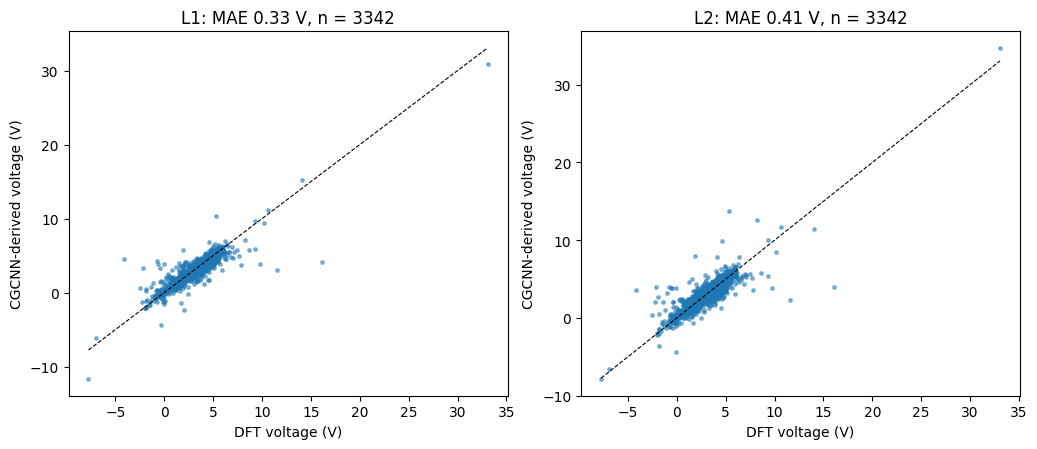

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from pymatgen.core import Composition
warnings.filterwarnings("ignore")

# ---- the claim: fixed BEFORE you look at any result. Change these only before running this cell, never after. ----
X_MAX_VOLT_ERROR = 0.25      # volts: the mean absolute error of CGCNN-derived average voltages must be at most this
Y_MIN_SPEARMAN   = 0.85      # rank correlation with the DFT voltages across all electrode pairs must be at least this

D = "/content/drive/MyDrive/cgcnn_run"
pairs = pd.read_csv(f"{D}/mp_pairs.csv"); lab = pd.read_csv(f"{D}/mp_labels.csv").set_index("id")

def voltage_from_ef(f_ch, f_dis, ef_ch, ef_dis, ion="Li", z=1):
    # average voltage (V vs ion metal) from formation energies per atom (eV/atom) of the charged / discharged endpoints
    cc, cd = Composition(f_ch), Composition(f_dis)
    fw_c = Composition({e: a for e, a in cc.items() if e.symbol != ion})
    fw_d = Composition({e: a for e, a in cd.items() if e.symbol != ion})
    ref = next(iter(fw_c.elements))                       # normalise both endpoints to the same framework amount
    sc, sd = 1 / fw_c[ref], 1 / fw_d[ref]
    n_c, n_d = cc[ion] * sc, cd[ion] * sd                 # working ions per framework unit
    e_c, e_d = ef_ch * cc.num_atoms * sc, ef_dis * cd.num_atoms * sd   # eV per framework unit
    return -(e_d - e_c) / (z * (n_d - n_c))

def safe_v(r, ef_ch, ef_dis):
    try: return voltage_from_ef(r.f_ch, r.f_dis, ef_ch, ef_dis)
    except Exception: return np.nan

# ---- sanity check first: DFT voltages rebuilt from formation energies should match MP's own average_voltage ----
pairs["v_dft"] = [safe_v(r, lab.ef[r.id_ch], lab.ef[r.id_dis]) for r in pairs.itertuples()]
dd = (pairs.v_dft - pairs.v_mp).abs()
print(f"{len(pairs)} electrode pairs, {int(pairs.v_dft.isna().sum())} could not be converted | rebuilt DFT voltage vs MP average_voltage: "
      f"median |diff| {dd.median():.3f} V, 90th pct {dd.quantile(.9):.3f} V  (should be small; if not, tell me before trusting anything below)")
pairs = pairs.dropna(subset=["v_dft"]).copy()

# ---- the experiment: voltages from CGCNN-predicted formation energies, for each hold-out level ----
rows, kept = [], {}
for lvl in ("L1", "L2"):
    f = f"{D}/run_mp_{lvl}/test_predictions.csv"
    if not os.path.exists(f): print(f"[{lvl}] no predictions yet: run its training cell first"); continue
    p = pd.read_csv(f).set_index("id")
    d = pairs[pairs.id_ch.isin(p.index) & pairs.id_dis.isin(p.index)].copy()
    d["v_ml"] = [safe_v(r, p.y_pred[r.id_ch], p.y_pred[r.id_dis]) for r in d.itertuples()]
    d = d.dropna(subset=["v_ml"]); d["err"] = (d.v_ml - d.v_dft).abs()
    win = d.v_dft.between(2.5, 4.5)                                       # the voltage window that matters for cathodes
    top, sel = d.v_dft >= d.v_dft.quantile(.9), d.v_ml >= d.v_ml.quantile(.9)
    ends = pd.concat([d.id_ch, d.id_dis]).unique()
    rows.append(dict(level=lvl, pairs=len(d), ef_MAE_at_endpoints=(p.y_pred[ends] - p.y_true[ends]).abs().mean(),
                     voltage_MAE=d.err.mean(), voltage_median=d.err.median(), voltage_p90=d.err.quantile(.9),
                     dummy_voltage_MAE=(d.v_dft - d.v_dft.mean()).abs().mean(), spearman=spearmanr(d.v_ml, d.v_dft)[0],
                     window_pairs=int(win.sum()), window_MAE=d.err[win].mean(), window_spearman=spearmanr(d.v_ml[win], d.v_dft[win])[0],
                     top10pct_found=(top & sel).sum() / top.sum()))
    d["chemsys"] = lab.chemsys[d.id_dis].values
    d.to_csv(f"{D}/voltage_eval_{lvl}.csv", index=False); kept[lvl] = d
res = pd.DataFrame(rows).set_index("level")
print("\n" + res.round(3).T.to_string())
print("\n(dummy_voltage_MAE = error of always guessing the mean DFT voltage; top10pct_found = share of the best 10% of pairs the model also puts in its top 10%)")
for lvl, r in res.iterrows():
    print(f"[{lvl}] voltage MAE {r.voltage_MAE:.3f} V vs limit {X_MAX_VOLT_ERROR}: {'PASS' if r.voltage_MAE <= X_MAX_VOLT_ERROR else 'FAIL'}"
          f"  |  Spearman {r.spearman:.3f} vs limit {Y_MIN_SPEARMAN}: {'PASS' if r.spearman >= Y_MIN_SPEARMAN else 'FAIL'}")

# ---- which chemistries fail, and the figure ----
for lvl, d in kept.items():
    g = d.groupby("chemsys").err.agg(["count", "mean"])
    print(f"\n[{lvl}] worst chemical systems (at least 5 pairs), mean voltage error in V:")
    print(g[g["count"] >= 5].nlargest(8, "mean").round(3).to_string())
if kept:
    fig, ax = plt.subplots(1, len(kept), figsize=(5.2 * len(kept), 4.6), squeeze=False)
    for a, (lvl, d) in zip(ax[0], kept.items()):
        a.scatter(d.v_dft, d.v_ml, s=6, alpha=.5); lim = [d.v_dft.min(), d.v_dft.max()]; a.plot(lim, lim, "k--", lw=.8)
        a.set(xlabel="DFT voltage (V)", ylabel="CGCNN-derived voltage (V)", title=f"{lvl}: MAE {d.err.mean():.2f} V, n = {len(d)}")
    plt.tight_layout(); plt.savefig(f"{D}/voltage_parity.png", dpi=150); plt.show()

## 11. Diagnostics
- 95% intervals from resampling whole chemical systems
- share of pairs within 0.1 / 0.25 / 0.5 V
- a post-hoc view restricted to 0–6 V DFT voltage (not the pre-registered criterion)
- exact decomposition of the voltage error into endpoint errors (independent vs shared)

[L1] decomposition check: rebuilt vs measured voltage error differ by at most 1.0e-13 V
[L2] decomposition check: rebuilt vs measured voltage error differ by at most 7.2e-14 V

==================== L1 ====================
voltage MAE 0.331 V (95% CI 0.306-0.356) | Spearman 0.925 (95% CI 0.908-0.941)
share of pairs within 0.10 / 0.25 / 0.50 V of DFT: 28% / 58% / 81%
POST-HOC, DFT voltage 0-6 V only: 3229 of 3342 pairs (113 outside) | MAE 0.295 V | Spearman 0.924 | best-10% found 75%
endpoint formation-energy errors: correlation 0.19 | mean |error| 0.024 eV/atom
voltage MAE if endpoint errors were independent 0.457 V | actual 0.331 V | if both endpoints had the same error 0.020 V
voltage error by working ions transferred per framework unit (dn):
              count  median   mean
dn                                
(0.0, 0.1]       27   0.515  0.751
(0.1, 0.25]     381   0.342  0.517
(0.25, 0.5]     852   0.262  0.385
(0.5, 1.0]     1591   0.181  0.294
(1.0, 100.0]    491   0.114  0.187
v

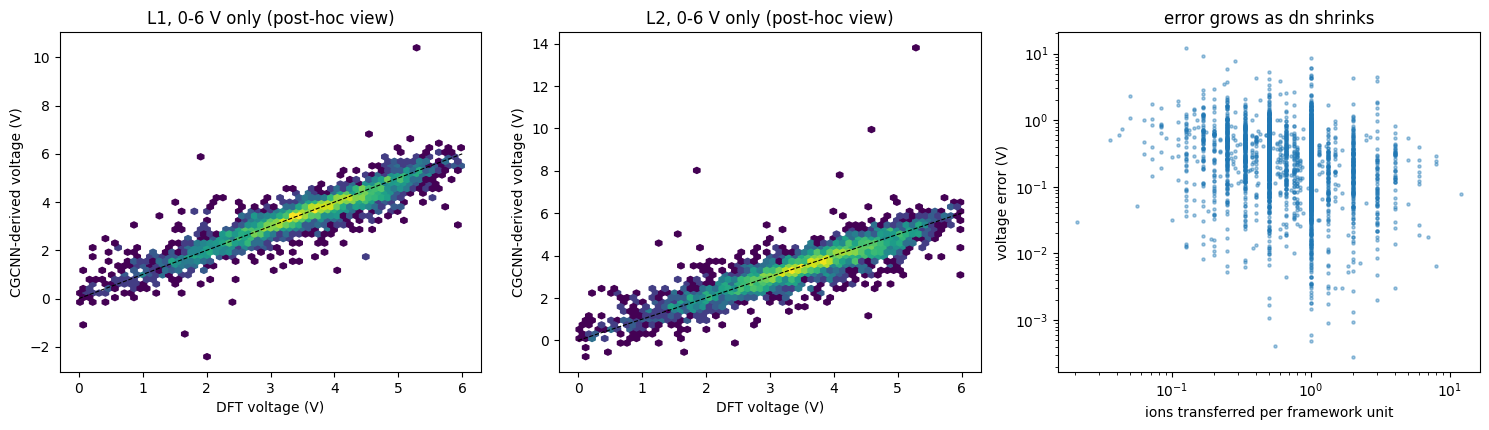

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
import importlib.util, subprocess, sys
if importlib.util.find_spec("pymatgen") is None: subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pymatgen"], check=True)
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from pymatgen.core import Composition
warnings.filterwarnings("ignore")
D = "/content/drive/MyDrive/cgcnn_run"; rng = np.random.default_rng(0)
lab = pd.read_csv(f"{D}/mp_labels.csv").set_index("id")                         # float64 MP labels: the same truth Cell 10 used

def sizes(f_ch, f_dis, ion="Li"):
    # atoms per framework unit at each endpoint, and working ions transferred per framework unit
    cc, cd = Composition(f_ch), Composition(f_dis)
    ref = next(e for e in cc.elements if e.symbol != ion)
    sc, sd = 1 / cc[ref], 1 / cd[ref]
    return cc.num_atoms * sc, cd.num_atoms * sd, cd[ion] * sd - cc[ion] * sc

def cluster_boot(d, fn, n=1000):
    # 95% interval when whole chemical systems are resampled (pairs from one system are not independent)
    groups = [g.index.values for _, g in d.groupby("chemsys")]
    vals = [fn(d.loc[np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])]) for _ in range(n)]
    return np.percentile(vals, [2.5, 97.5])

res = {}
for lvl in ("L1", "L2"):
    f = f"{D}/voltage_eval_{lvl}.csv"
    if not os.path.exists(f): print(f"[{lvl}] run Cell 10 after its training cell first"); continue
    d = pd.read_csv(f)
    p = pd.read_csv(f"{D}/run_mp_{lvl}/test_predictions.csv").set_index("id"); e = p.y_pred - lab.ef.reindex(p.index)
    d["N_ch"], d["N_dis"], d["dn"] = np.array([sizes(a, b) for a, b in zip(d.f_ch, d.f_dis)]).T
    d["de_ch"], d["de_dis"] = e[d.id_ch].values, e[d.id_dis].values                  # signed formation-energy errors at the two endpoints (eV/atom)
    chk = np.abs(np.abs(-(d.N_dis * d.de_dis - d.N_ch * d.de_ch) / d.dn) - d.err).max()
    print(f"[{lvl}] decomposition check: rebuilt vs measured voltage error differ by at most {chk:.1e} V" + ("" if chk < 1e-6 else "   <-- WARNING: do not trust the decomposition below, tell me"))
    res[lvl] = d

for lvl, d in res.items():
    print(f"\n==================== {lvl} ====================")
    # 1) the pre-registered numbers with honest intervals
    mae_ci = cluster_boot(d, lambda x: x.err.mean()); sp_ci = cluster_boot(d, lambda x: spearmanr(x.v_ml, x.v_dft)[0], n=300)
    print(f"voltage MAE {d.err.mean():.3f} V (95% CI {mae_ci[0]:.3f}-{mae_ci[1]:.3f}) | Spearman {spearmanr(d.v_ml, d.v_dft)[0]:.3f} (95% CI {sp_ci[0]:.3f}-{sp_ci[1]:.3f})")
    print("share of pairs within 0.10 / 0.25 / 0.50 V of DFT:", " / ".join(f"{(d.err <= t).mean():.0%}" for t in (.1, .25, .5)))

    # 2) POST-HOC: the DFT voltage column contains non-physical pairs; look at 0-6 V only (not the pre-registered criterion)
    ph = d[d.v_dft.between(0, 6)]
    print(f"POST-HOC, DFT voltage 0-6 V only: {len(ph)} of {len(d)} pairs ({len(d) - len(ph)} outside) | MAE {ph.err.mean():.3f} V | Spearman {spearmanr(ph.v_ml, ph.v_dft)[0]:.3f}"
          f" | best-10% found {((ph.v_dft >= ph.v_dft.quantile(.9)) & (ph.v_ml >= ph.v_ml.quantile(.9))).sum() / (ph.v_dft >= ph.v_dft.quantile(.9)).sum():.0%}")

    # 3) why is a 0.03 eV/atom error a 0.3 V error? exact decomposition: v_err = -(N_dis*de_dis - N_ch*de_ch) / dn
    shuf = np.mean([(np.abs(d.N_dis.values * d.de_dis.values[rng.permutation(len(d))] - d.N_ch.values * d.de_ch.values) / d.dn.values).mean() for _ in range(200)])
    same = (np.abs((d.N_dis - d.N_ch) * (d.de_ch + d.de_dis) / 2) / d.dn).mean()
    print(f"endpoint formation-energy errors: correlation {np.corrcoef(d.de_ch, d.de_dis)[0, 1]:.2f} | mean |error| {pd.concat([d.de_ch, d.de_dis]).abs().mean():.3f} eV/atom")
    print(f"voltage MAE if endpoint errors were independent {shuf:.3f} V | actual {d.err.mean():.3f} V | if both endpoints had the same error {same:.3f} V")
    g = d.groupby(pd.cut(d.dn, [0, .1, .25, .5, 1, 100]), observed=True).err.agg(["count", "median", "mean"])
    print("voltage error by working ions transferred per framework unit (dn):"); print(g.round(3).to_string())
    g = d.groupby(pd.cut(d.N_dis, [0, 4, 8, 12, 20, 1000]), observed=True).err.agg(["count", "median", "mean"])
    print("voltage error by atoms per framework unit (discharged state):"); print(g.round(3).to_string())

if len(res) == 2:
    a, b = res["L1"], res["L2"]
    if a.id_ch.equals(b.id_ch) and a.id_dis.equals(b.id_dis):
        diff = b.assign(dd=b.err.values - a.err.values)
        ci = cluster_boot(diff, lambda x: x.dd.mean())
        print(f"\nL2 minus L1 voltage MAE: {diff.dd.mean():+.3f} V (95% CI {ci[0]:+.3f} to {ci[1]:+.3f}); one training seed each, so seed-to-seed noise is NOT in this interval")

fig, ax = plt.subplots(1, len(res) + 1, figsize=(5 * (len(res) + 1), 4.4), squeeze=False)
for a_, (lvl, d) in zip(ax[0], res.items()):
    q = d[d.v_dft.between(0, 6)]; a_.hexbin(q.v_dft, q.v_ml, gridsize=60, bins="log", mincnt=1); a_.plot([0, 6], [0, 6], "k--", lw=.8)
    a_.set(xlabel="DFT voltage (V)", ylabel="CGCNN-derived voltage (V)", title=f"{lvl}, 0-6 V only (post-hoc view)")
if res:
    d = list(res.values())[-1]; ax[0][-1].scatter(d.dn, d.err, s=5, alpha=.4); ax[0][-1].set(xscale="log", yscale="log", xlabel="ions transferred per framework unit", ylabel="voltage error (V)", title="error grows as dn shrinks")
plt.tight_layout(); plt.savefig(f"{D}/voltage_diagnostics.png", dpi=150); plt.show()

## 12. Two more seeds for the L2 hold-out

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
import sys, importlib; sys.path.insert(0, "/content/drive/MyDrive/cgcnn_run")
import fastcgcnn as fc; importlib.reload(fc)
D = fc.DRIVE
for s in (1, 2):                                                                  # two more training seeds for the L2 hold-out (seed 0 is your existing run)
    fc.train(f"{D}/graphs_mp_all.npz", f"{D}/mp_split_L2.json", f"{D}/run_mp_L2_s{s}", seed=s)   # about an hour each; resumes after a disconnect

device: cuda Tesla T4
train / val / test = 120099 6321 25125 (no overlap, checked)
epoch   0 | val MAE 0.1994 (best 0.1994) | 16s
epoch   1 | val MAE 0.1224 (best 0.1224) | 16s
epoch   2 | val MAE 0.1319 (best 0.1224) | 16s
epoch   5 | val MAE 0.1142 (best 0.1142) | 20s
epoch  10 | val MAE 0.1015 (best 0.0731) | 19s
epoch  15 | val MAE 0.0895 (best 0.0716) | 19s
epoch  20 | val MAE 0.0650 (best 0.0650) | 19s
epoch  25 | val MAE 0.0910 (best 0.0605) | 19s
epoch  30 | val MAE 0.0812 (best 0.0545) | 19s
epoch  35 | val MAE 0.0700 (best 0.0529) | 19s
epoch  40 | val MAE 0.0616 (best 0.0529) | 19s
epoch  45 | val MAE 0.0590 (best 0.0513) | 19s
epoch  50 | val MAE 0.0495 (best 0.0489) | 19s
epoch  55 | val MAE 0.0502 (best 0.0484) | 19s
epoch  60 | val MAE 0.0461 (best 0.0461) | 19s
epoch  65 | val MAE 0.0440 (best 0.0440) | 19s
epoch  70 | val MAE 0.0514 (best 0.0440) | 19s
epoch  75 | val MAE 0.0482 (best 0.0440) | 19s
epoch  80 | val MAE 0.0482 (best 0.0437) | 19s
epoch  85 | val MAE 0.04

## 13. Ensemble and selective prediction (exploratory)
Not part of the pre-registered claim.

training seeds available: 3 ['run_mp_L2', 'run_mp_L2_s1', 'run_mp_L2_s2']

              voltage_MAE_V  spearman
run_mp_L2             0.409     0.895
run_mp_L2_s1          0.400     0.897
run_mp_L2_s2          0.412     0.897
seed-to-seed spread of voltage MAE: mean 0.407 V, std 0.007 V

ENSEMBLE of 3 seeds: voltage MAE 0.368 V vs limit 0.25: FAIL  |  Spearman 0.911 vs limit 0.85: PASS
does disagreement flag bad pairs? Spearman(disagreement, |error|) = 0.22
most-confident pairs kept    n  MAE (V)  within 0.25 V  within 0.5 V
                      10%  334    0.250          0.656         0.859
                      25%  835    0.275          0.640         0.853
                      50% 1671    0.296          0.598         0.841
                      75% 2506    0.305          0.567         0.825
                     100% 3342    0.368          0.522         0.784
largest share of pairs kept with MAE <= 0.25 V: 10%


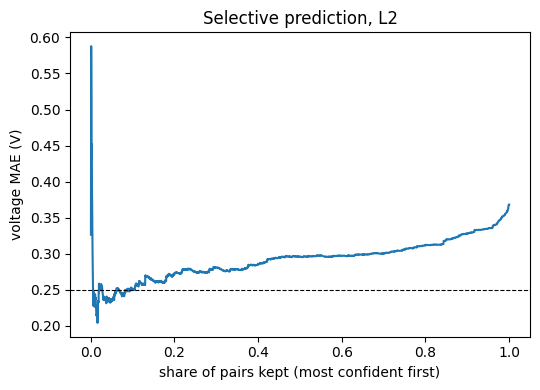

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
import importlib.util, subprocess, sys
if importlib.util.find_spec("pymatgen") is None: subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pymatgen"], check=True)
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from pymatgen.core import Composition
warnings.filterwarnings("ignore")
D = "/content/drive/MyDrive/cgcnn_run"
X_MAX_VOLT_ERROR, Y_MIN_SPEARMAN = 0.25, 0.85          # the SAME limits as Cell 10: do not change them now

def voltage_from_ef(f_ch, f_dis, ef_ch, ef_dis, ion="Li", z=1):
    cc, cd = Composition(f_ch), Composition(f_dis)
    fw_c = Composition({e: a for e, a in cc.items() if e.symbol != ion})
    fw_d = Composition({e: a for e, a in cd.items() if e.symbol != ion})
    ref = next(iter(fw_c.elements))
    sc, sd = 1 / fw_c[ref], 1 / fw_d[ref]
    n_c, n_d = cc[ion] * sc, cd[ion] * sd
    e_c, e_d = ef_ch * cc.num_atoms * sc, ef_dis * cd.num_atoms * sd
    return -(e_d - e_c) / (z * (n_d - n_c))

runs = [r for r in ("run_mp_L2", "run_mp_L2_s1", "run_mp_L2_s2") if os.path.exists(f"{D}/{r}/test_predictions.csv")]
print("training seeds available:", len(runs), runs)
P = pd.concat({r: pd.read_csv(f"{D}/{r}/test_predictions.csv").set_index("id").y_pred for r in runs}, axis=1)    # ids x seeds
d = pd.read_csv(f"{D}/voltage_eval_L2.csv")[["id_ch", "id_dis", "f_ch", "f_dis", "v_dft", "chemsys"]]
V = pd.DataFrame({r: [voltage_from_ef(a, b, P[r][i], P[r][j]) for a, b, i, j in zip(d.f_ch, d.f_dis, d.id_ch, d.id_dis)] for r in runs})

# ---- 1) seed-to-seed noise: how much of the L2 number is luck? ----
err = V.sub(d.v_dft, axis=0).abs()
per_seed = pd.DataFrame({"voltage_MAE_V": err.mean(), "spearman": [spearmanr(V[r], d.v_dft)[0] for r in runs]}, index=runs)
print("\n" + per_seed.round(3).to_string())
if len(runs) > 1: print(f"seed-to-seed spread of voltage MAE: mean {per_seed.voltage_MAE_V.mean():.3f} V, std {per_seed.voltage_MAE_V.std():.3f} V")

# ---- 2) the ensemble against the limits you committed to ----
ens = V.mean(axis=1); e_ens = (ens - d.v_dft).abs(); sp = spearmanr(ens, d.v_dft)[0]
print(f"\nENSEMBLE of {len(runs)} seeds: voltage MAE {e_ens.mean():.3f} V vs limit {X_MAX_VOLT_ERROR}: {'PASS' if e_ens.mean() <= X_MAX_VOLT_ERROR else 'FAIL'}"
      f"  |  Spearman {sp:.3f} vs limit {Y_MIN_SPEARMAN}: {'PASS' if sp >= Y_MIN_SPEARMAN else 'FAIL'}")

# ---- 3) can the ensemble tell you WHICH voltages to trust? (needs 3 seeds) ----
if len(runs) >= 3:
    unc = V.std(axis=1)                                                      # disagreement between seeds, in volts
    print(f"does disagreement flag bad pairs? Spearman(disagreement, |error|) = {spearmanr(unc, e_ens)[0]:.2f}")
    order = unc.sort_values().index; n = len(order)
    cum = e_ens.loc[order].cumsum().values / np.arange(1, n + 1)             # MAE when keeping only the k most-agreeing pairs
    rows = []
    for c in (.1, .25, .5, .75, 1.0):
        k = int(n * c); s_ = e_ens.loc[order[:k]]
        rows.append((f"{c:.0%}", k, s_.mean(), (s_ <= .25).mean(), (s_ <= .5).mean()))
    print(pd.DataFrame(rows, columns=["most-confident pairs kept", "n", "MAE (V)", "within 0.25 V", "within 0.5 V"]).round(3).to_string(index=False))
    ok = np.where(cum <= X_MAX_VOLT_ERROR)[0]
    print(f"largest share of pairs kept with MAE <= {X_MAX_VOLT_ERROR} V: " + (f"{(ok.max() + 1) / n:.0%}" if len(ok) else "none"))
    plt.figure(figsize=(5.5, 4)); plt.plot(np.arange(1, n + 1) / n, cum); plt.axhline(X_MAX_VOLT_ERROR, color="k", ls="--", lw=.8)
    plt.xlabel("share of pairs kept (most confident first)"); plt.ylabel("voltage MAE (V)"); plt.title("Selective prediction, L2")
    plt.tight_layout(); plt.savefig(f"{D}/voltage_selective_L2.png", dpi=150); plt.show()

## 14. Environment and results export

In [1]:
from google.colab import drive; drive.mount("/content/drive")
import sys, os, shutil, subprocess, importlib.metadata as md
sys.path.insert(0, "/content/drive/MyDrive/cgcnn_run"); import fastcgcnn as fc
fc.ensure_repo()
D = fc.DRIVE; R = f"{D}/results"; os.makedirs(R, exist_ok=True)

lines = [f"python {sys.version.split()[0]}"]
for p in ("torch", "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "pymatgen", "pymatgen-core", "mp-api", "emmet-core", "matminer"):
    try: lines.append(f"{p} {md.version(p)}")
    except md.PackageNotFoundError: pass
import torch; lines.append("gpu: " + (torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none in this session"))
lines.append("CGCNN repository commit: " + subprocess.run(["git", "-C", fc.REPO, "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip())
lines.append("Materials Project database release: 2026.09.28 (printed by Section 7)")
lines.append("note: packages were installed unpinned; these are the versions in the session that ran this cell")
open(f"{R}/environment.txt", "w").write("\n".join(lines) + "\n"); print("\n".join(lines))

# figures and small tables for the repository's results/ folder
for f in ("run1/gate0_summary.png", "voltage_parity.png", "voltage_diagnostics.png", "voltage_selective_L2.png",
          "run1/history.csv", "voltage_eval_L1.csv", "voltage_eval_L2.csv"):
    if os.path.exists(f"{D}/{f}"): shutil.copy(f"{D}/{f}", f"{R}/{os.path.basename(f)}")
    else: print("missing (skipped):", f)
print("copied to", R, "->", sorted(os.listdir(R)))

Mounted at /content/drive
python 3.13.18
torch 2.14.1+cpu
numpy 2.4.6
pandas 2.2.3
scipy 1.16.3
scikit-learn 1.6.1
matplotlib 3.10.0
gpu: none in this session
CGCNN repository commit: f42ab233c4ee0c416879d6bc2d22a264418413ad
Materials Project database release: 2026.09.28 (printed by Section 7)
note: packages were installed unpinned; these are the versions in the session that ran this cell
copied to /content/drive/MyDrive/cgcnn_run/results -> ['environment.txt', 'gate0_summary.png', 'history.csv', 'voltage_diagnostics.png', 'voltage_eval_L1.csv', 'voltage_eval_L2.csv', 'voltage_parity.png', 'voltage_selective_L2.png']


## Limitations and future work
- Li-ion pairs only; one training seed at L1 and three at L2.
- One Materials Project release; GGA / GGA+U labels. The thermo type was assumed (see the note in Section 7) and validated.
- L1 does not remove near-duplicate polymorphs of the electrode compounds from training; L2 removes whole chemical systems and is the more honest number.
- The ensemble and selective-prediction analysis was not pre-registered and is exploratory.
- Next step: a pair-aware model that predicts the endpoint energy difference directly. If endpoint errors were fully shared, the voltage MAE would be about 0.02 V (a bound, not a promise).